In [1]:
import scanpy as sc
import os
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
import seaborn as sns
import numpy as np
import random
import decoupler as dc
SEED = 0
np.random.seed(SEED)
random.seed(SEED)

from matplotlib.colors import LinearSegmentedColormap

my_cmap = LinearSegmentedColormap.from_list(
    "soft_rdbl", ["#53b1dc", "#FFFFFF", "#EE6677"], N=256
)





figure_save_path = "../results/Fig_5_figures"
os.makedirs(figure_save_path, exist_ok=True)

In [4]:
adata = sc.read("../data/WL_fibroblasts_min.h5ad")

## Fig. 5b

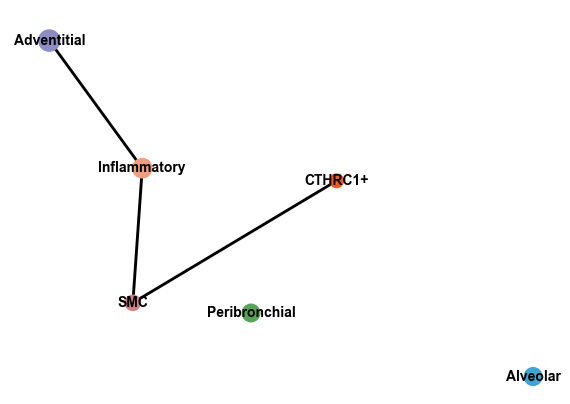

In [7]:
sc.pl.paga(adata, threshold=0.2, show=False, frameon=False,  layout='fa')
plt.show()

In [5]:
from py_monocle import (
    learn_graph,
    order_cells,
    compute_cell_states,
    regression_analysis,
    differential_expression_genes,
)
import networkx as nx
from scipy.sparse import issparse, csr_matrix, isspmatrix_csr

def peseudo_time_monocle(adata, X_rep='X_umap', root_cells=1000, gif_name=None, figsize=(8, 4)):
    adata = adata.copy()

    sparse_X = issparse(adata.X)
    if sparse_X and not isspmatrix_csr(adata.X):
        adata.X = _adata.X.tocsr()
    expression_matrix = adata.X
    features = adata.var_names
    mat = adata.obsm[X_rep]
    projected_points, mst, centroids = learn_graph(matrix=mat, kmeans_seed=SEED)
    
    pseudotime = order_cells(
        mat, centroids,
        mst=mst,
        projected_points=projected_points,
        root_cells=root_cells,
    )
    pseudotime = pseudotime.reshape(pseudotime.shape[0], 1)
    adata.obs['pseudotime'] = pseudotime

    edges = np.array(mst.nonzero()).T

    G = nx.Graph()
    for edge in edges:
        G.add_edge(edge[0], edge[1])

    # leaves branch points
    leaves = [node for node, degree in G.degree() if degree == 1]
    branch_points = [node for node, degree in G.degree() if degree > 2]

    fig, axs = plt.subplots(1, 2, figsize=figsize)
    axs = axs.flatten()
    
    plot_configs = [
        ('pseudotime', my_cmap, None, axs[0]),
        ('annotation', None, None, axs[1]),
    ]

    for color, cmap, vmax, ax in plot_configs:
        sc.pl.embedding(adata, basis=X_rep, color=color, show=False, ax=ax, cmap='viridis', frameon=False, vmax=vmax, s=20)
        
        # edges
        for edge in edges:
            ax.plot(centroids[edge, 0], centroids[edge, 1], c="black", linewidth=1)

        # branch points
        if branch_points:
            ax.scatter(centroids[branch_points, 0], centroids[branch_points, 1],
                       color='yellow', s=30, edgecolors='black', label="_nolegend_", zorder=5)
        # leaves
        if leaves:
            ax.scatter(centroids[leaves, 0], centroids[leaves, 1],
                       color='green', s=30, edgecolors='black', label="_nolegend_", zorder=5)

        # ax.legend(loc='best', fontsize=8)

    plt.tight_layout()
    # plt.show()
    # print("Show")

    key = 'pseudotime_graph'
    adata.uns.setdefault(key, {})

    # store trajectory nodes / edges
    adata.uns[key]["centroids"] = np.asarray(centroids, dtype=np.float32)
    adata.uns[key]["edges"] = np.asarray(edges, dtype=np.int32)

    # store leaf / branch point node ids (indices in centroids)
    adata.uns[key]["leaves"] = np.asarray(leaves, dtype=np.int32)
    adata.uns[key]["branch_points"] = np.asarray(branch_points, dtype=np.int32)
    
    morans_i_scores, pvalues, adjusted_pvalues = differential_expression_genes(
        expression_matrix,
        projected_cells=projected_points,
    )
    morani_results = pd.DataFrame(
        {
            "Moran's I score": morans_i_scores,
            "P-values": np.round(pvalues, 4),
            "Adjusted P-values": np.round(adjusted_pvalues, 4),
            "Gene Indices": np.arange(len(morans_i_scores))
        },
        index=pd.Series(features, name="Genes"),
    ).sort_values("Moran's I score", ascending=False)

    # return pseudotime, edges, centroids, branch_points, leaves, morani_results
    return fig, adata


In [6]:
ad = adata[~adata.obs['annotation'].isin(['SMC', 'Peribronchial', 'Adventitial'])].copy()

## Fig. 5c

/users/PAS2148/tiger/miniconda3/envs/scRNA/lib/python3.9/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/users/PAS2148/tiger/miniconda3/envs/scRNA/lib/python3.9/site-packages/scanpy/metrics/_common.py:62: UserWarning: 2217 variables were constant, will return nan for these.
  warnings.warn(


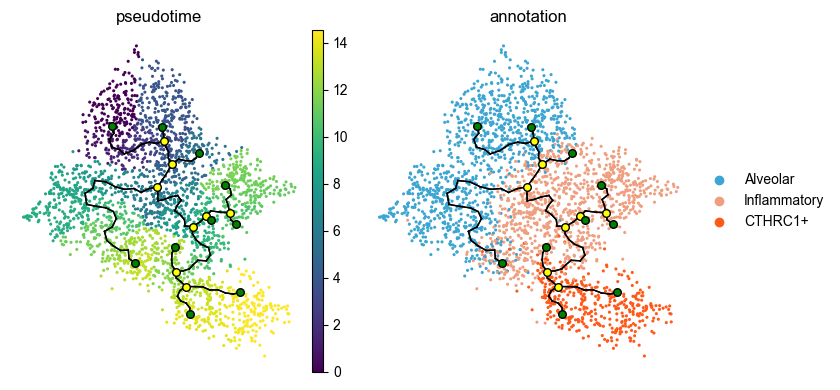

In [7]:
c_adata = ad[ad.obs['Condition'] == 'IPF upper lobe'].copy()
c_adata.obs['cell_id'] = range(c_adata.n_obs)
fig, adata_mon = peseudo_time_monocle(c_adata, X_rep='X_umap', root_cells=1123, figsize = (8.5, 4))
fig.savefig(f"{figure_save_path}/ipf_ul_monocle.pdf", bbox_inches = 'tight')
plt.show()

In [8]:
adata_mon.write("../data/ipf_ul_monocle_min.h5ad")

/users/PAS2148/tiger/miniconda3/envs/scRNA/lib/python3.9/site-packages/scanpy/metrics/_common.py:62: UserWarning: 2217 variables were constant, will return nan for these.
  warnings.warn(


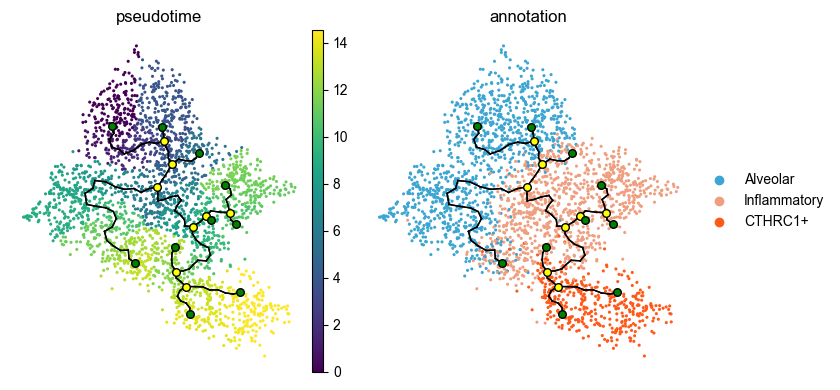

In [9]:
c_adata = ad[ad.obs['Condition'] == 'IPF upper lobe'].copy()
um = c_adata.obsm["X_umap"]
c_adata.obs['cell_id'] = range(c_adata.n_obs)
fig, adata_mon = peseudo_time_monocle(c_adata, X_rep='X_umap', root_cells=1123, figsize = (8.5, 4))
fig.savefig(f"{figure_save_path}/ipf_ul_monocle.pdf", bbox_inches = 'tight')
plt.show()

In [10]:
adata_mon.write("../data/ipf_ul_monocle_min.h5ad")

/users/PAS2148/tiger/miniconda3/envs/scRNA/lib/python3.9/site-packages/scanpy/metrics/_common.py:62: UserWarning: 2134 variables were constant, will return nan for these.
  warnings.warn(


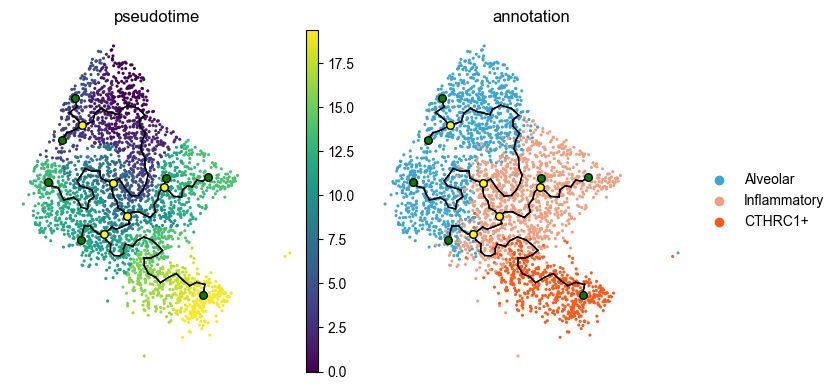

In [11]:
c_adata = ad[ad.obs['Condition'] == 'IPF lower lobe'].copy()
c_adata.obs['cell_id'] = range(c_adata.n_obs)
fig, adata_mon = peseudo_time_monocle(c_adata, X_rep='X_umap', root_cells=1085, figsize = (8.5, 4))
fig.savefig(f"{figure_save_path}/ipf_ll_monocle.pdf", bbox_inches = 'tight')
plt.show()

In [12]:
adata_mon.write("../data/ipf_ll_monocle_min.h5ad")

## Fig. 5d

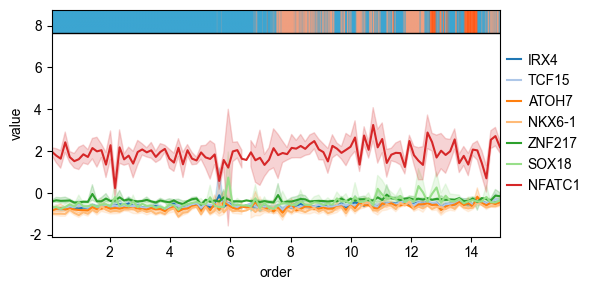

In [2]:
adata_control = sc.read("../data/aged_control_monocle_min.h5ad")
hallmark = dc.op.collectri()
dc.mt.ulm(data=adata_control, net=hallmark)
control_score = dc.pp.get_obsm(adata=adata_control, key="score_ulm")
hlm = dc.tl.rankby_order(
    adata=control_score,
    order="pseudotime",
)

bin_hlm = dc.pp.bin_order(
    adata=control_score,
    order="pseudotime",
    names=['IRX4', 'TCF15', 'ATOH7', 'NKX6-1', 'ZNF217', 'SOX18','NFATC1'],
    label="annotation",
)

dc.pl.order(
    df=bin_hlm,
    mode="line",
    figsize=(6, 3),
)
plt.savefig(f"{figure_save_path}/TF_aged_control.pdf",  bbox_inches='tight')
plt.show()

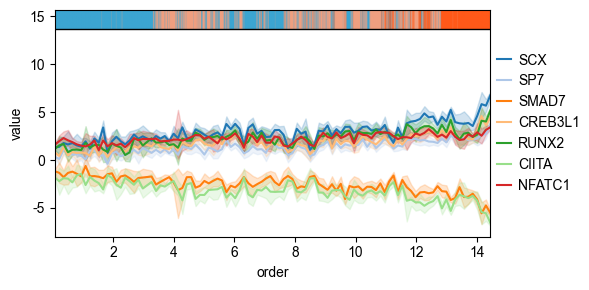

In [3]:
adata_ipf_ul = sc.read("../data/ipf_ul_monocle_min.h5ad")

dc.mt.ulm(data=adata_ipf_ul, net=hallmark)
score_ipf_ul = dc.pp.get_obsm(adata=adata_ipf_ul, key="score_ulm")
hlm = dc.tl.rankby_order(
    adata=score_ipf_ul,
    order="pseudotime",
)

bin_hlm = dc.pp.bin_order(
    adata=score_ipf_ul,
    order="pseudotime",
    names=['SCX', 'SP7', 'SMAD7', 'CREB3L1', 'RUNX2', 'CIITA', 'NFATC1'],
    label="annotation",
)

dc.pl.order(
    df=bin_hlm,
    mode="line",
    figsize=(6, 3),
)
plt.savefig(f"{figure_save_path}/TF_ipf_ul.pdf",  bbox_inches='tight')
plt.show()

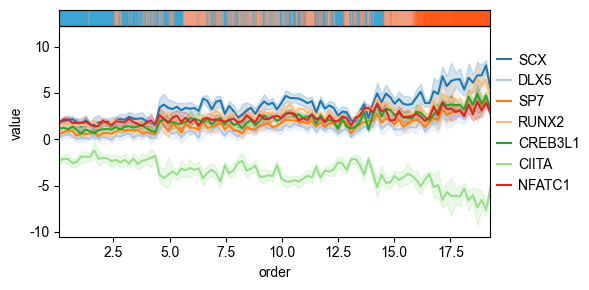

In [4]:
adata_ipf_ll = sc.read("../data/ipf_ll_monocle_min.h5ad")
hallmark = dc.op.collectri()
dc.mt.ulm(data=adata_ipf_ll, net=hallmark)
score_ipf_ll = dc.pp.get_obsm(adata=adata_ipf_ll, key="score_ulm")
hlm = dc.tl.rankby_order(
    adata=score_ipf_ll,
    order="pseudotime",
)
bin_hlm = dc.pp.bin_order(
    adata=score_ipf_ll,
    order="pseudotime",
    names=['SCX', 'DLX5', 'SP7', 'RUNX2', 'CREB3L1', 'CIITA', 'NFATC1'],
    label="annotation",
)

dc.pl.order(
    df=bin_hlm,
    mode="line",
    figsize=(6, 3),
)
plt.savefig(f"{figure_save_path}/TF_ipf_ll.pdf",  bbox_inches='tight')
plt.show()

## Fig. 5e

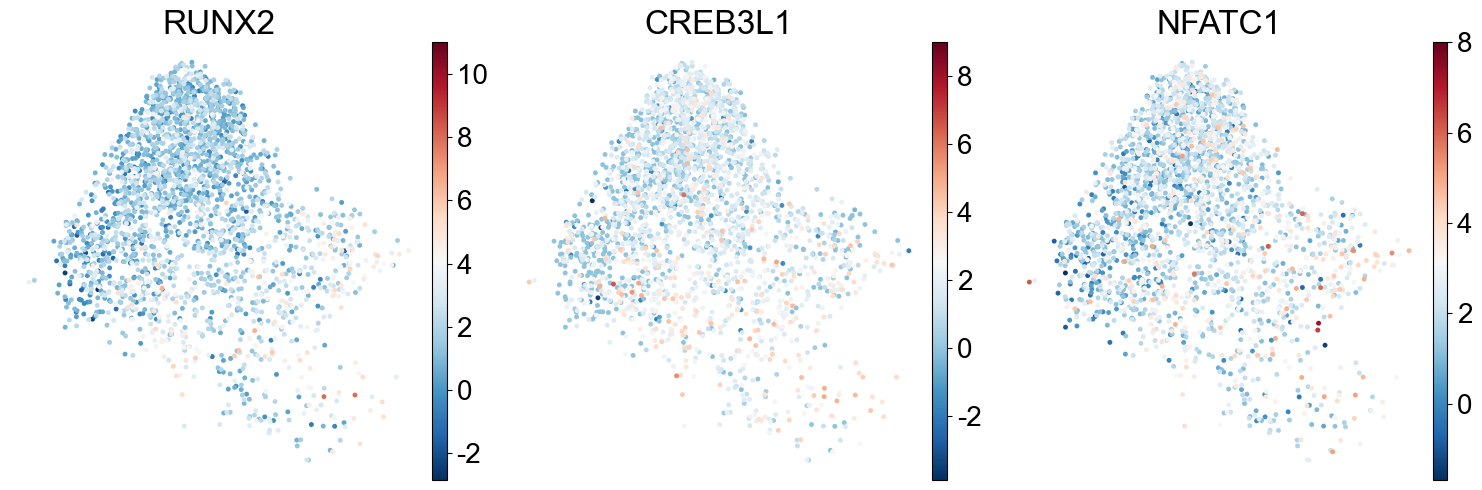

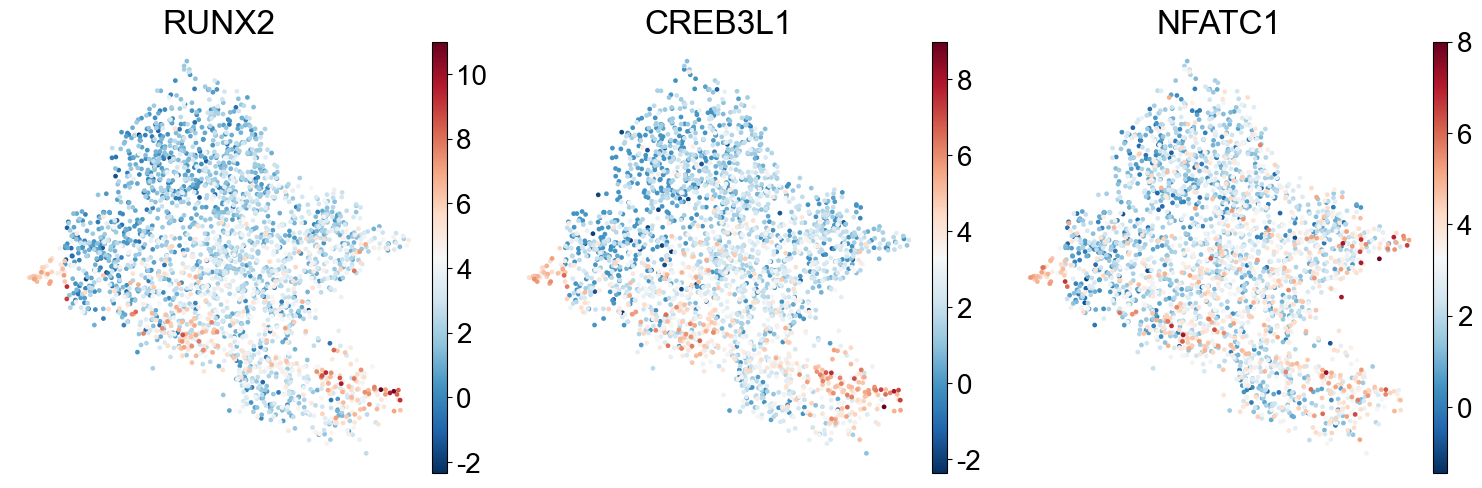

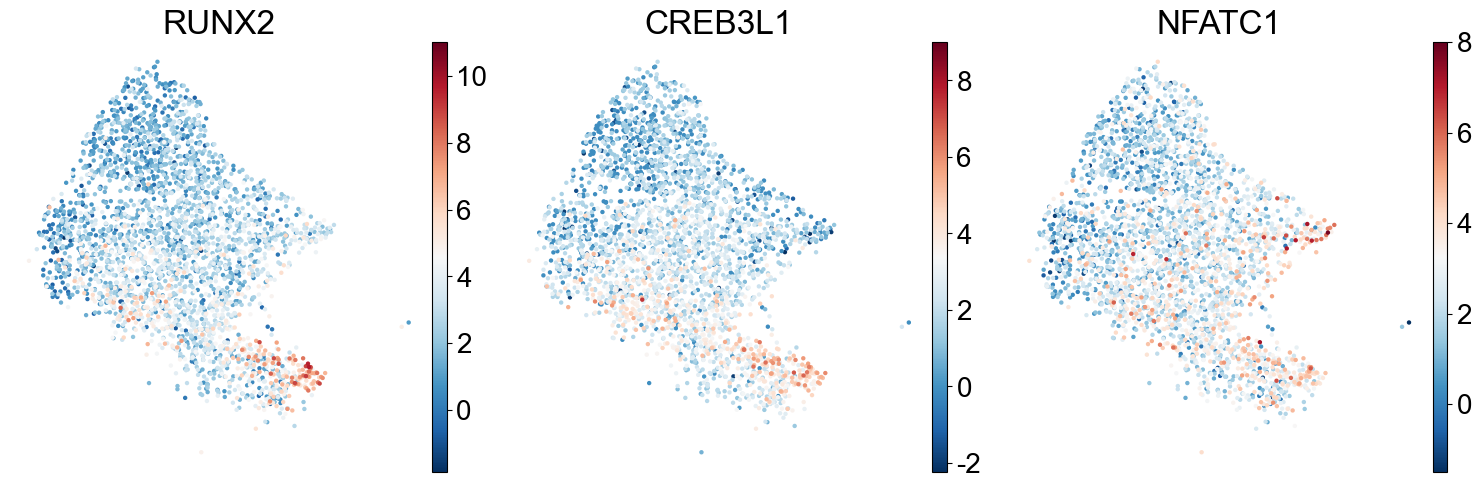

In [22]:
datasets = {'control': control_score, 'ipf_ul': score_ipf_ul, 'ipf_ll': score_ipf_ll}
genes = ['RUNX2', 'CREB3L1', 'NFATC1']
vmaxs = [11, 9, 8]

for name, adata in datasets.items():
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes = axes.flatten()
    
    with plt.rc_context({'font.size': 20}):
        for i, (gene, vmax) in enumerate(zip(genes, vmaxs)):
            sc.pl.umap(adata, color=gene, cmap='RdBu_r', frameon=False, vmax=vmax, ax=axes[i], show=False)
    
    # plt.suptitle(f'{name}', fontsize=20, y=1.02)
    plt.tight_layout()
    plt.savefig(f'{figure_save_path}/RUNX2_CREB3L1_NFATC1_{name}.pdf', bbox_inches='tight')
    plt.show()